**Evaluating an A/B Test**

The product is an online platform for reading comics.
Some comic episodes are free; to view all episodes, users purchase virtual currency.

The platform uses email to notify users about comic updates, provide personalized content recommendations, and share promotional offers.

On August 1, an A/B test was launched regarding a new logic for sending emails to users.
Group A is the control group. Notification frequency: 1 email every 3–4 days.
Group B is the test group. The frequency of email notifications is doubled.

Notification frequency remains consistent from the moment of registration in both groups. For users whose group assignment changed after registration, the frequency typically doubles and then remains stable.

On August 25, the test should be evaluated.

**Additional questions**:
1. Is there sufficient data to make a decision?
2. Could the test have been concluded earlier?
3. Should CUPED be applied to this test?
4. What data could help evaluate the test more quickly?

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import seaborn as sns
import numpy as np


In [31]:
# loading data stored in csv
users = pd.read_csv("/content/users.csv")
transactions = pd.read_csv("/content/transactions.csv")
reading_log = pd.read_csv("/content/reading_log.csv")
comics = pd.read_csv("/content/comics.csv")
visits = pd.read_csv("/content/visits.csv")



# EDA

In [32]:
missing_pct_users = users.isna().mean() * 100
print(f"Users missing values:\n{missing_pct_users}\n")

missing_pct_transactions = transactions.isna().mean() * 100
print(f"Transactions missing values:\n{missing_pct_transactions}\n")

missing_pct_reading_log = reading_log.isna().mean() * 100
print(f"Reading log missing values:\n{missing_pct_reading_log}\n")

missing_pct_comics = comics.isna().mean() * 100
print(f"Comics missing values:\n{missing_pct_comics}\n")

missing_pct_visits = visits.isna().mean() * 100
print(f"Visits missing values:\n{missing_pct_visits}")

Users missing values:
id              0.0
created_at      0.0
is_validated    0.0
country_code    0.0
default_os      0.0
split_group     0.0
dtype: float64

Transactions missing values:
id            0.0
amount        0.0
created_at    0.0
user_id       0.0
dtype: float64

Reading log missing values:
id                0.0
user_id           0.0
date              0.0
comic_id          0.0
count_episodes    0.0
dtype: float64

Comics missing values:
comic_id     0.0
author_id    0.0
dtype: float64

Visits missing values:
id         0.0
user_id    0.0
date       0.0
dtype: float64


In [33]:
print(f"Users:\n{users.shape}\n{users.describe()}")
print(f"\nTransactions:\n{transactions.shape}\n{transactions.describe()}")
print(f"\nReading log:\n{reading_log.shape}\n{reading_log.describe()}")
print(f"\nComics:\n{comics.shape}\n{comics.describe()}")
print(f"\nVisits:\n{visits.shape}\n{visits.describe()}")

Users:
(430961, 6)
                  id   country_code
count  430961.000000  430961.000000
mean   215481.000000       2.100754
std    124407.869018       0.538365
min         1.000000       1.000000
25%    107741.000000       2.000000
50%    215481.000000       2.000000
75%    323221.000000       2.000000
max    430961.000000       3.000000

Transactions:
(296680, 4)
                  id         amount        user_id
count  296680.000000  296680.000000  296680.000000
mean   148340.500000      16.422610  148159.006576
std     85644.283269       9.338232  108160.662430
min         1.000000      10.000000       9.000000
25%     74170.750000      10.000000   59175.000000
50%    148340.500000      10.000000  126474.000000
75%    222510.250000      30.000000  217987.000000
max    296680.000000      30.000000  430915.000000

Reading log:
(1416068, 5)
                 id       user_id      comic_id  count_episodes
count  1.416068e+06  1.416068e+06  1.416068e+06    1.416068e+06
mean   7.080345e

In [34]:
# changing to proper data format
# passing coerce argument in order to change date field to nat, and then drop those rows (to properly determine data by test date)
users["created_at"] = pd.to_datetime(users["created_at"], format="%Y-%m-%d %H:%M:%S")
transactions["created_at"] = pd.to_datetime(transactions["created_at"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
transactions = transactions.dropna(subset=["created_at"])

reading_log["date"] = pd.to_datetime(reading_log["date"], format="%Y-%m-%d")

visits["date"] = pd.to_datetime(visits["date"], format="%Y-%m-%d", errors="coerce")
visits = visits.dropna(subset=["date"])


# A/B Testing Exploration

In [35]:
# filtering data by test dates
test_start_date = "2022-08-01"
test_end_date = "2022-08-25"

test_transactions = transactions[(transactions["created_at"] >= test_start_date) &
                                 (transactions["created_at"] <= test_end_date)]

test_reading_log = reading_log[(reading_log["date"] >= test_start_date) &
                               (reading_log["date"] <= test_end_date)]
test_visits = visits[(visits["date"] >= test_start_date) &
                     (visits["date"] <= test_end_date)]



In [36]:
# filtering only those users who gave permission for receiving letters
users_with_permission = users[users["is_validated"] == True].copy()

# grouping and aggregating transactions by each user
user_transactions = (test_transactions.groupby("user_id").
                     agg(total_revenue=("amount", "sum"), transactions_count=("user_id", "count"))
                     .reset_index())

# grouping and aggregating reading log (episodes read by each user)
user_reading_log = (test_reading_log.groupby("user_id").
                    agg(total_read_episodes=("count_episodes", "sum"))
                    .reset_index())

# grouping and aggregating visits (by each user)
user_visits = (test_visits
               .groupby("user_id")
               .agg(total_visits=("date", "nunique"))
               .reset_index())


In [37]:
# merging aggregated data in one single dataframe
# using left join, as there may be users with no transactions/read episodes/visits,
# left join adds those users as well
test_users_and_transactions = users_with_permission.merge(user_transactions, left_on="id", right_on="user_id", how="left")
with_reading_log = test_users_and_transactions.merge(user_reading_log, left_on="id", right_on="user_id", how="left")
transactions_and_log_and_visits = with_reading_log.merge(user_visits, left_on="id", right_on="user_id", how="left")

transactions_and_log_and_visits[["total_revenue", "transactions_count", "total_read_episodes", "total_visits"]] = transactions_and_log_and_visits[["total_revenue", "transactions_count", "total_read_episodes", "total_visits"]].fillna(0)

# add binary conversion metric to indicate whether spend any money (total_revenue in this case > 0)
transactions_and_log_and_visits["any_revenue"] = (transactions_and_log_and_visits["total_revenue"] > 0.0).astype(int)



In [38]:
# split data by two groups
group_a = transactions_and_log_and_visits[transactions_and_log_and_visits["split_group"] == "a"]
group_b = transactions_and_log_and_visits[transactions_and_log_and_visits["split_group"] == "b"]

len_group_a = group_a.shape[0]
len_group_b = group_b.shape[0]
print(f"Rows of A group: {len_group_a}")
print(f"Rows of B group: {len_group_b}\n")

# average revenue per user
avg_revenue_group_a = group_a["total_revenue"].mean()
avg_revenue_group_b = group_b["total_revenue"].mean()

# performing t-test on revenue, as there are distinct groups in testing
t_stat, p_val_ttest = stats.ttest_ind(group_a["total_revenue"], group_b["total_revenue"], equal_var=False)

# calculating z-test for conversion rate (by average revenue by user)
converted_group_a = group_a["any_revenue"].mean()
converted_group_b = group_b["any_revenue"].mean()
# z-test
# getting sum of successful actions per group
succ_revenue_by_group = [group_a["any_revenue"].sum(), group_b["any_revenue"].sum()]
len_of_groups = [len(group_a), len(group_b)]
z_stat, p_val_conversion = sm.stats.proportions_ztest(succ_revenue_by_group, len_of_groups)

print(f"Group A avg_revenue_per_user: {avg_revenue_group_a:.4f}.\nGroup B avg_revenue_per_user: {avg_revenue_group_b:.4f}")
print(f"T-test p-value: {p_val_ttest:.4f}")
print(f"Conversion rate from group A: {converted_group_a:.4f} ({(converted_group_a * 100).round(2)}%).\nConversion rate from group B: {converted_group_b:.4f} ({(converted_group_b * 100).round(2)}%)")
print(f"Conversion p-value: {p_val_conversion:.2f}")


Rows of A group: 89004
Rows of B group: 61895

Group A avg_revenue_per_user: 6.6567.
Group B avg_revenue_per_user: 6.7010
T-test p-value: 0.8730
Conversion rate from group A: 0.0465 (4.65%).
Conversion rate from group B: 0.0486 (4.86%)
Conversion p-value: 0.06


In [39]:
pre_test_transactions = transactions[transactions['created_at'] < test_start_date]
pre_user_revenue = pre_test_transactions.groupby("user_id")["amount"].sum().rename("pre_revenue")
pre_user_conversion = (pre_test_transactions.groupby("user_id")["amount"].sum() > 0 ).astype(int).rename("pre_any_revenue")

pre_df = transactions_and_log_and_visits.merge(pre_user_revenue, left_on="id", right_index=True, how="left")
pre_df = pre_df.merge(pre_user_conversion, left_on="id", right_index=True, how="left")

pre_df["pre_revenue"] = pre_df["pre_revenue"].fillna(0)
pre_df["pre_any_revenue"] = pre_df["pre_any_revenue"].fillna(0)

group_a_pre_test = pre_df[pre_df["split_group"] == "a"]
group_b_pre_test = pre_df[pre_df["split_group"] == "b"]

pre_test_converted_group_a = group_a_pre_test["pre_any_revenue"].mean()
pre_test_converted_group_b = group_b_pre_test["pre_any_revenue"].mean()

# comparing the users structure before test (pre-test metrics)
user_structure_comparison = pd.DataFrame({
    "Metric": ["Pre-revenue Mean", "Total Users", "Conversion (Any Revenue)"],
    "Group A": [group_a_pre_test.get("pre_revenue", pd.Series([0])).mean(),
     len(group_a_pre_test), pre_test_converted_group_a],
    "Group B": [group_b_pre_test.get("pre_revenue", pd.Series([0])).mean(),
                len(group_b_pre_test), pre_test_converted_group_b]
})
print(f"-- User Groups Structure Comparison --")
print(user_structure_comparison)


-- User Groups Structure Comparison --
                     Metric       Group A       Group B
0          Pre-revenue Mean      5.752213      4.120042
1               Total Users  89004.000000  61895.000000
2  Conversion (Any Revenue)      0.025886      0.016657


Before the test start, the group A had bigger revenue per user (5.75 against 4.12).

Moreover, the conversion to any purchase is higher as well (~2.59% for group A, and ~ 1.67% in group B).

In [40]:
# outliers check
print("Revenue Outliers Check")
print(f"Group A max revenue by user: {group_a["total_revenue"].max()}")
print(f"Group B max revenue by user: {group_b["total_revenue"].max()}")

# discovering quantiles, in order to find users with the biggest revenue value
print(f"\nGroup A Revenue Quatiles:\n{group_a["total_revenue"].quantile([0.8, 0.9, 0.95, 0.99, 1])}")
print(f"\nGroup B Revenue Quatiles:\n{group_b["total_revenue"].quantile([0.8, 0.9, 0.95, 0.99, 1])}")

# bootstrap method for calculating confidence interval on the mean of A/B
boot_differences = []
a_arr = group_a["total_revenue"]
b_arr = group_b["total_revenue"]
for _ in range(1000):  # 1000 simulations
    # extracting random value from the set for both groups
    sample_a = np.random.choice(a_arr, size=len(a_arr), replace=True)
    sample_b = np.random.choice(b_arr, size=len(b_arr), replace=True)
    # get difference between means of two groups
    boot_differences.append(sample_b.mean() - sample_a.mean())

# cutting the 2.5% from both ends
lower = np.percentile(boot_differences, 2.5)
upper = np.percentile(boot_differences, 97.5)
mean_diff = np.mean(boot_differences)

print(f"\nBootstap Mean Difference (B - A): {mean_diff:.4f}")
print(f"95% Confidence Interval for Difference: [{lower:.4f}, {upper:.4f}]")


Revenue Outliers Check
Group A max revenue by user: 1320.0
Group B max revenue by user: 1180.0

Group A Revenue Quatiles:
0.80       0.0
0.90       0.0
0.95       0.0
0.99     140.0
1.00    1320.0
Name: total_revenue, dtype: float64

Group B Revenue Quatiles:
0.80       0.0
0.90       0.0
0.95       0.0
0.99     140.0
1.00    1180.0
Name: total_revenue, dtype: float64

Bootstap Mean Difference (B - A): 0.0427
95% Confidence Interval for Difference: [-0.4704, 0.5850]


Up to the 95th percentile, total revenue per user is equeal to 0 in both groups. This indicates that over 95% of users are non-paying, and revenue is driven mostly by few customers (top < 5%) (high-spending users).

The high end of the distribution is identical acroos both groups: the 99th percentile sits at 140.0 for both A and B, while maximum spending is similar (1320 for group A, 1180 for group B). This confirms that the test outcome is not distorted by extreme outlier in both groups.

**Bootstap Mean Difference**

The mean difference (B - A) is 0.0528, indicating no practical improvement in Average Revenue by User.

**95% Confidence Interval**: [-0.4880, 0.5621]: Because the confidence interval spans almost simetrically from 0, the observed difference is not statistically significant and may be coming just by random noise.

**Takeaway**: Rolling out new strategy of email notifications has a clear risk of zero financial return, providing no evidence of better revenue.

In [41]:
paying_a = group_a[group_a["total_revenue"] > 0]["total_revenue"]
paying_b = group_b[group_b["total_revenue"] > 0]["total_revenue"]
# average paying users only
arppu_a = paying_a.mean() if len(paying_a) > 0 else 0
arppu_b = paying_b.mean() if len(paying_b) > 0 else 0

t_stat_arppu, p_val_arppu = stats.ttest_ind(paying_a, paying_b, equal_var=False)

print("--- Risk Analysis: ARPPU (Paying Users Only) ---")
print(f"ARPPU Group A: {arppu_a:.4f}")
print(f"ARPPU Group B: {arppu_b:.4f}")
print(f"ARPPU p-value: {p_val_arppu:.4f}")

--- Risk Analysis: ARPPU (Paying Users Only) ---
ARPPU Group A: 143.1087
ARPPU Group B: 137.8856
ARPPU p-value: 0.2784


The average revenue per paying user stands at 143 for group A and 137 for group B, indicating a slight downward tick.

The independent t-test returns p-value of 0.27 (above 0.05 threshold), meaning that the observed difference is statistically insignificant and likely caused by random noise.

**Key Takeaway**: While not statistically harmful, variant B fails to improve monetization uplift among paying users. Combined with overall ARPU results and bootsrap confidence intervals, this confirms that launching variant B offers no financial upside.

In [ ]:
len_group_a = group_a.shape[0]
len_group_b = group_b.shape[0]
print(f"Rows of A group: {len_group_a}")
print(f"Rows of B group: {len_group_b}\n")

# average revenue per user
avg_revenue_group_a = group_a["total_revenue"].mean()
avg_revenue_group_b = group_b["total_revenue"].mean()

# performing t-test on revenue, as there are distinct groups in testing
t_stat, p_val_ttest = stats.ttest_ind(group_a["total_revenue"], group_b["total_revenue"], equal_var=False)

# calculating z-test for conversion rate (by average revenue by user)
converted_group_a = group_a["any_revenue"].mean()
converted_group_b = group_b["any_revenue"].mean()
# z-test
# getting sum of successful actions per group
succ_revenue_by_group = [group_a["any_revenue"].sum(), group_b["any_revenue"].sum()]
len_of_groups = [len(group_a), len(group_b)]
z_stat, p_val_conversion = sm.stats.proportions_ztest(succ_revenue_by_group, len_of_groups)

print(f"Group A avg_revenue_per_user: {avg_revenue_group_a:.4f}.\nGroup B avg_revenue_per_user: {avg_revenue_group_b:.4f}")
print(f"T-test p-value: {p_val_ttest:.4f}")
print(f"Conversion rate from group A: {converted_group_a:.4f} ({(converted_group_a * 100).round(2)}%).\nConversion rate from group B: {converted_group_b:.4f} ({(converted_group_b * 100).round(2)}%)")
print(f"Conversion p-value: {p_val_conversion:.2f}")


At this stage, doubling the number of emails has not resulted in a statistically significant change in revenue per user (a difference of 0.4 is merely noise, as confirmed by a p-value of 0.87).

Conversion to purchase increased but failed to reach the established threshold (p-value < 0.05), suggesting the result is due to noise or random data.

Therefore, it cannot currently be claimed that revenue or conversion to purchase have improved.

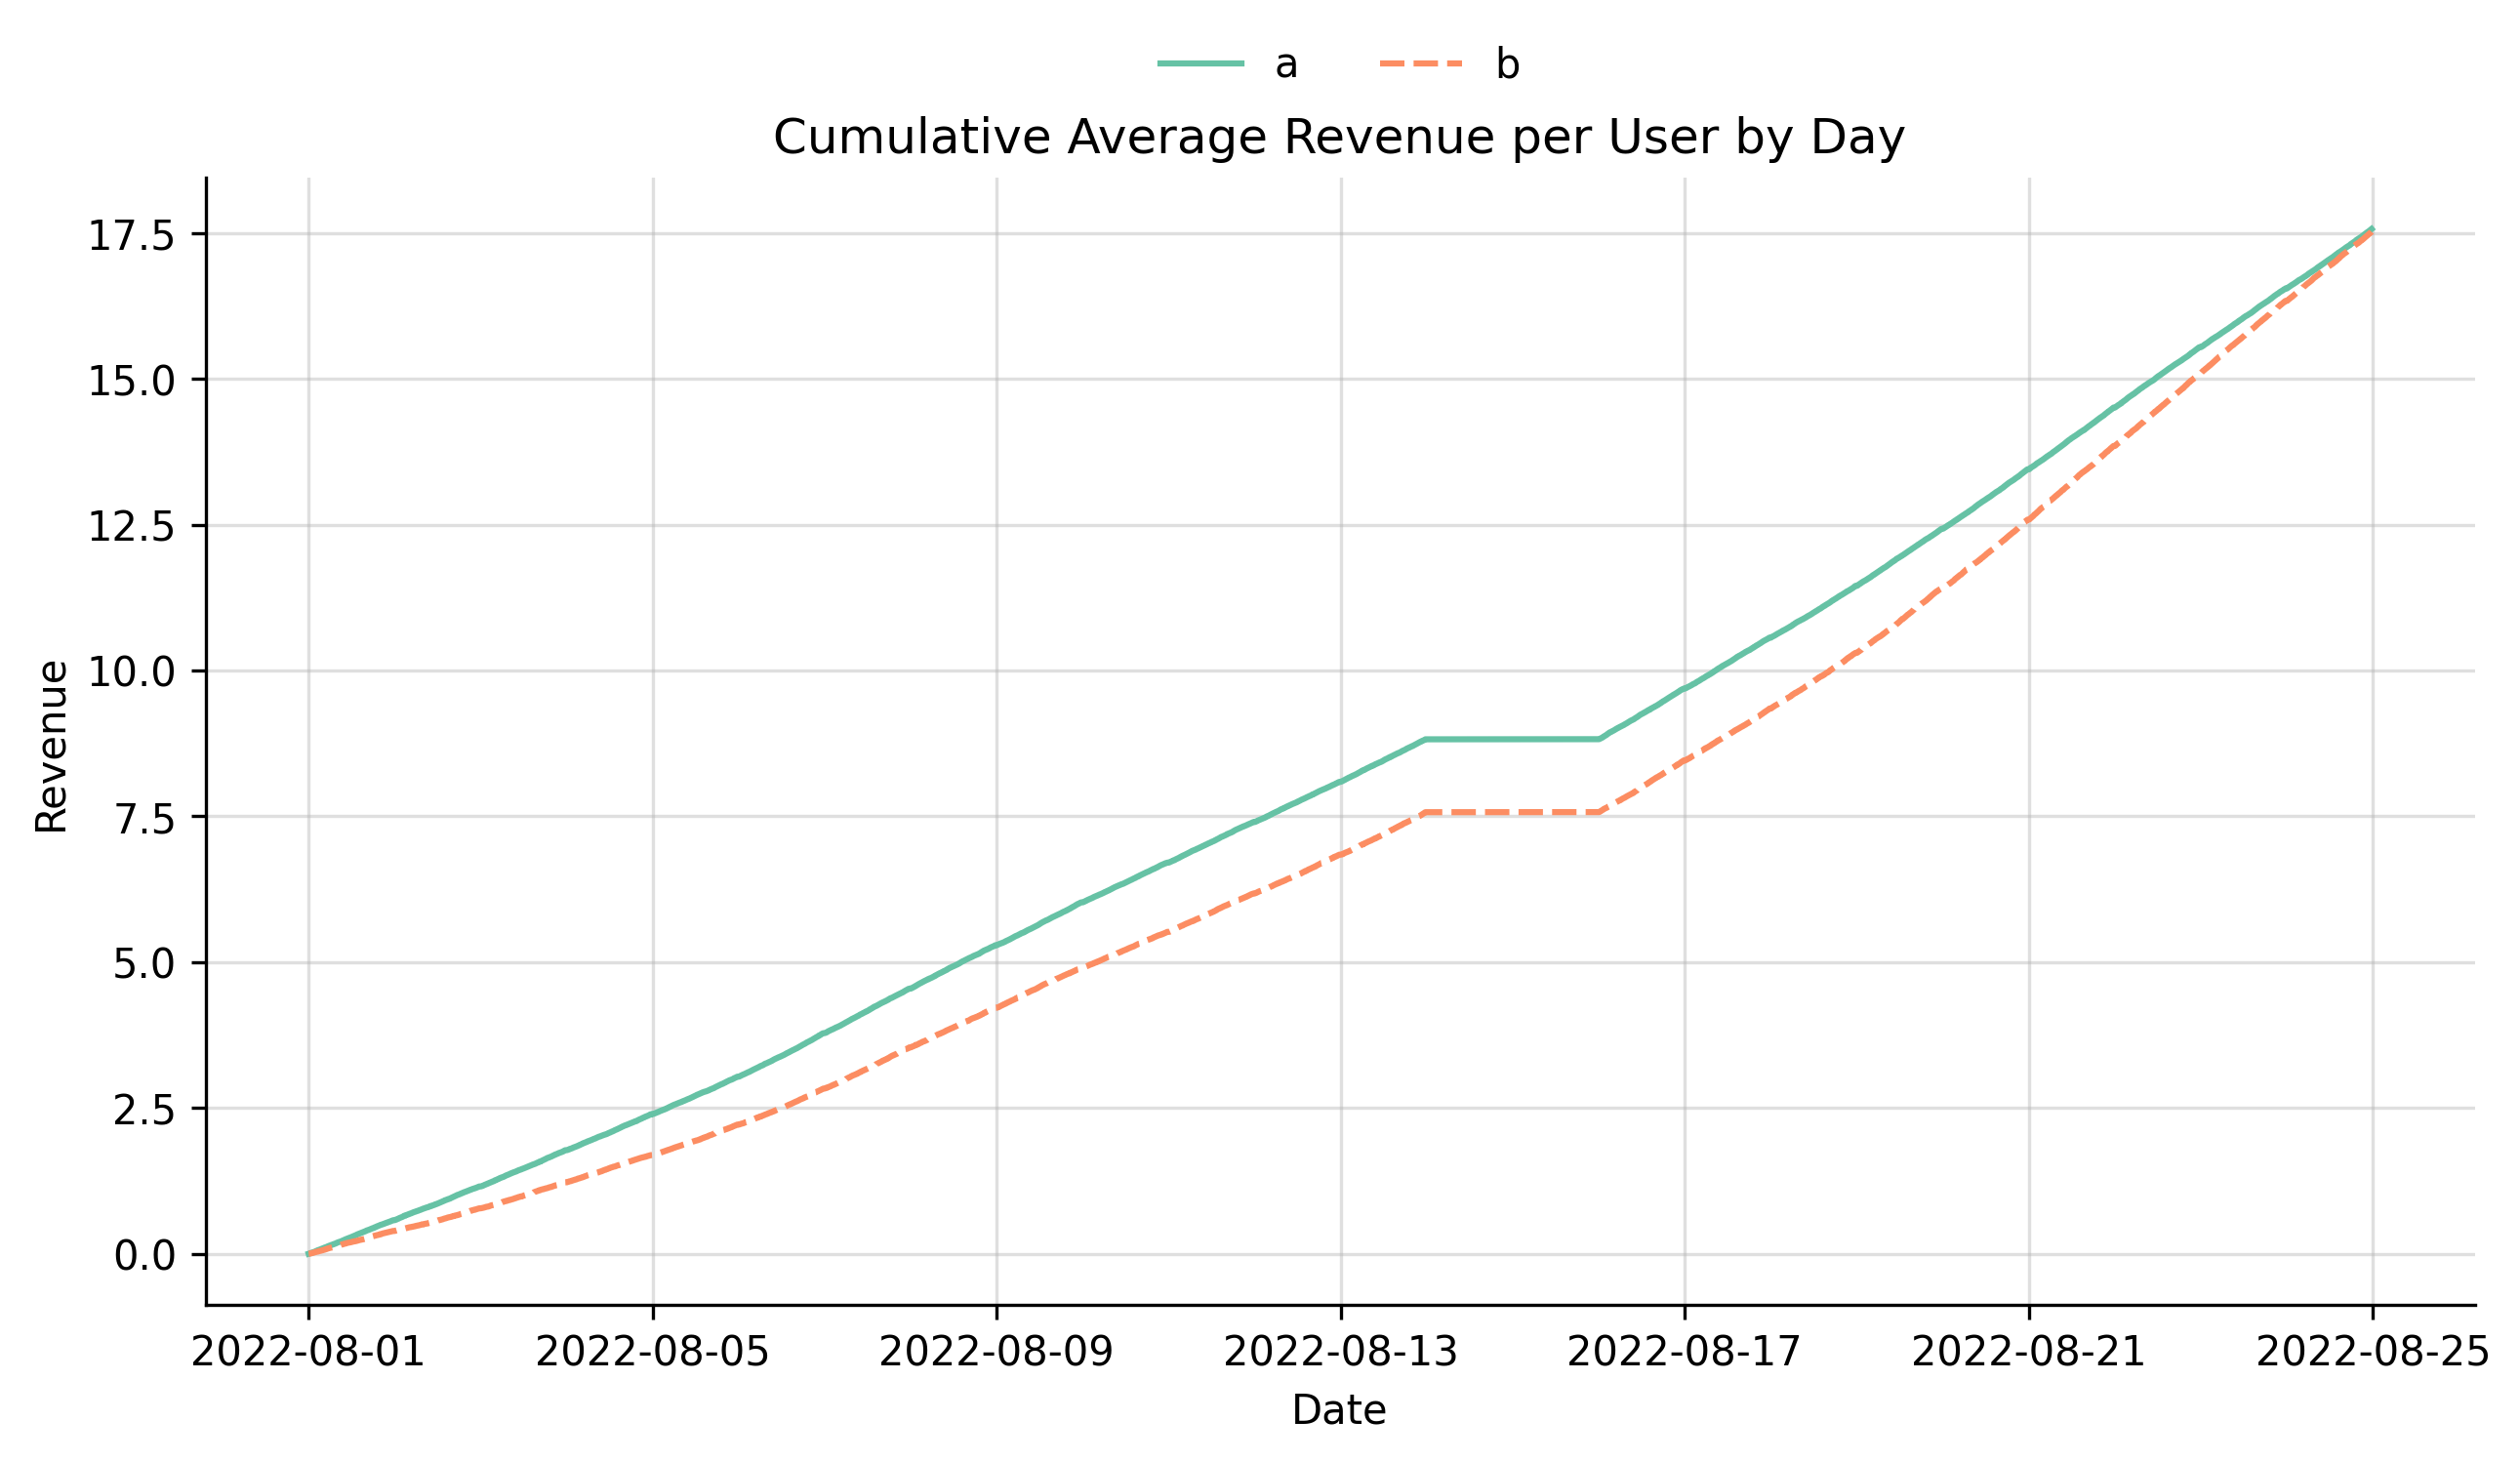

In [ ]:
# calculate daily revenue
df_merged = test_transactions.merge(
    users[["id", "split_group"]], left_on="user_id", right_on="id"
)
pivot_daily = (
    df_merged.pivot_table(index="created_at", columns="split_group", values="amount", aggfunc="sum")
    .fillna(0)
    .cumsum()
)

pivot_daily["a"] = pivot_daily["a"] / len_group_a
pivot_daily["b"] = pivot_daily["b"] / len_group_b

plt.figure(figsize=(10, 5), dpi=300)
sns.lineplot(data=pivot_daily, palette="Set2")
plt.title("Cumulative Average Revenue per User by Day")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.grid(linestyle="-", alpha=0.4)
plt.legend(bbox_to_anchor=(0.5, 1.15), loc="upper center", ncol=2, frameon=False)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.show()


The provided chart of cumulative revenue per user shows no significant difference in monetization between the groups.
Revenue accumulation in both groups aligns almost perfectly throughout the test cycle—though the test group shows a slower pace—and ultimately reaches the same final results.

Additionally, the chart displays flat segments around August 15–16, which may be due to a lack of transaction logs during that period.

In [ ]:
no_transactions_period = transactions[(transactions["created_at"] >= "2022-08-14") &
                                 (transactions["created_at"] <= "2022-08-15")]
print(no_transactions_period)

Empty DataFrame
Columns: [id, amount, created_at, user_id]
Index: []


A plateau was observed on the graph between August 14 and August 15. An examination of the raw data revealed a gap in the transaction table for this period. This could be due to either data failing to be added to the table or the dates being in an incorrect format, which led to their removal from the table during the initial stages of the analysis.

In [ ]:
# cuped
# take data before the start of testing
pre_test_transactions = transactions[transactions["created_at"] < test_start_date]
pre_user_revenue = pre_test_transactions.groupby("user_id")["amount"].sum().rename("pre_revenue")
df = transactions_and_log_and_visits.merge(pre_user_revenue, left_on="id", right_index=True, how="left")
df["pre_revenue"] = df["pre_revenue"].fillna(0)

# defining theta for cuped
theta_sample = df["total_revenue"].cov(df["pre_revenue"]) / df["pre_revenue"].var()
df["revenue_cuped"] = df["total_revenue"] - theta_sample * (
    df["pre_revenue"] - df["pre_revenue"].mean()
)
# performing t-test on cuped metric
ttest_cuped, p_val_cuped = stats.ttest_ind(df[df["split_group"] == "a"]["revenue_cuped"],
                                           df[df["split_group"] == "b"]["revenue_cuped"],
                                           equal_var=False)

print(f"Usual p-value: {p_val_ttest:.4f}")
print(f"CUPED p-value: {p_val_cuped:.4f}")

Usual p-value: 0.8730
CUPED p-value: 0.0000


In [ ]:
# visits to platform analysis
visits_a = group_a["total_visits"]
visits_b = group_b["total_visits"]

mean_visits_a = visits_a.mean()
mean_visits_b = visits_b.mean()

t_stat_visits, p_val_visits = stats.ttest_ind(visits_a, visits_b, equal_var=False)

print("Stats about Total Visits")
print(f"Group A mean visits: {mean_visits_a:.4f}")
print(f"Group B mean visits: {mean_visits_b:.4f}")
print(f"Visits t-test p-value: {p_val_visits:.4f}\n")

# read episodes analysis
episodes_a = group_a["total_read_episodes"]
episodes_b = group_b["total_read_episodes"]

mean_episodes_a = episodes_a.mean()
mean_episodes_b = episodes_b.mean()

t_stat_episodes, p_val_episodes = stats.ttest_ind(
    episodes_a, episodes_b, equal_var=False
)

print("Stats about Read Episodes")
print(f"Group A mean read episodes: {mean_episodes_a:.4f}")
print(f"Group B mean read episodes: {mean_episodes_b:.4f}")
print(f"Read episodes t-test p-value: {p_val_episodes:.4f}")


Stats about Total Visits
Group A mean visits: 2.2092
Group B mean visits: 2.8655
Visits t-test p-value: 0.0000

Stats about Read Episodes
Group A mean read episodes: 11.0747
Group B mean read episodes: 13.2845
Read episodes t-test p-value: 0.0000


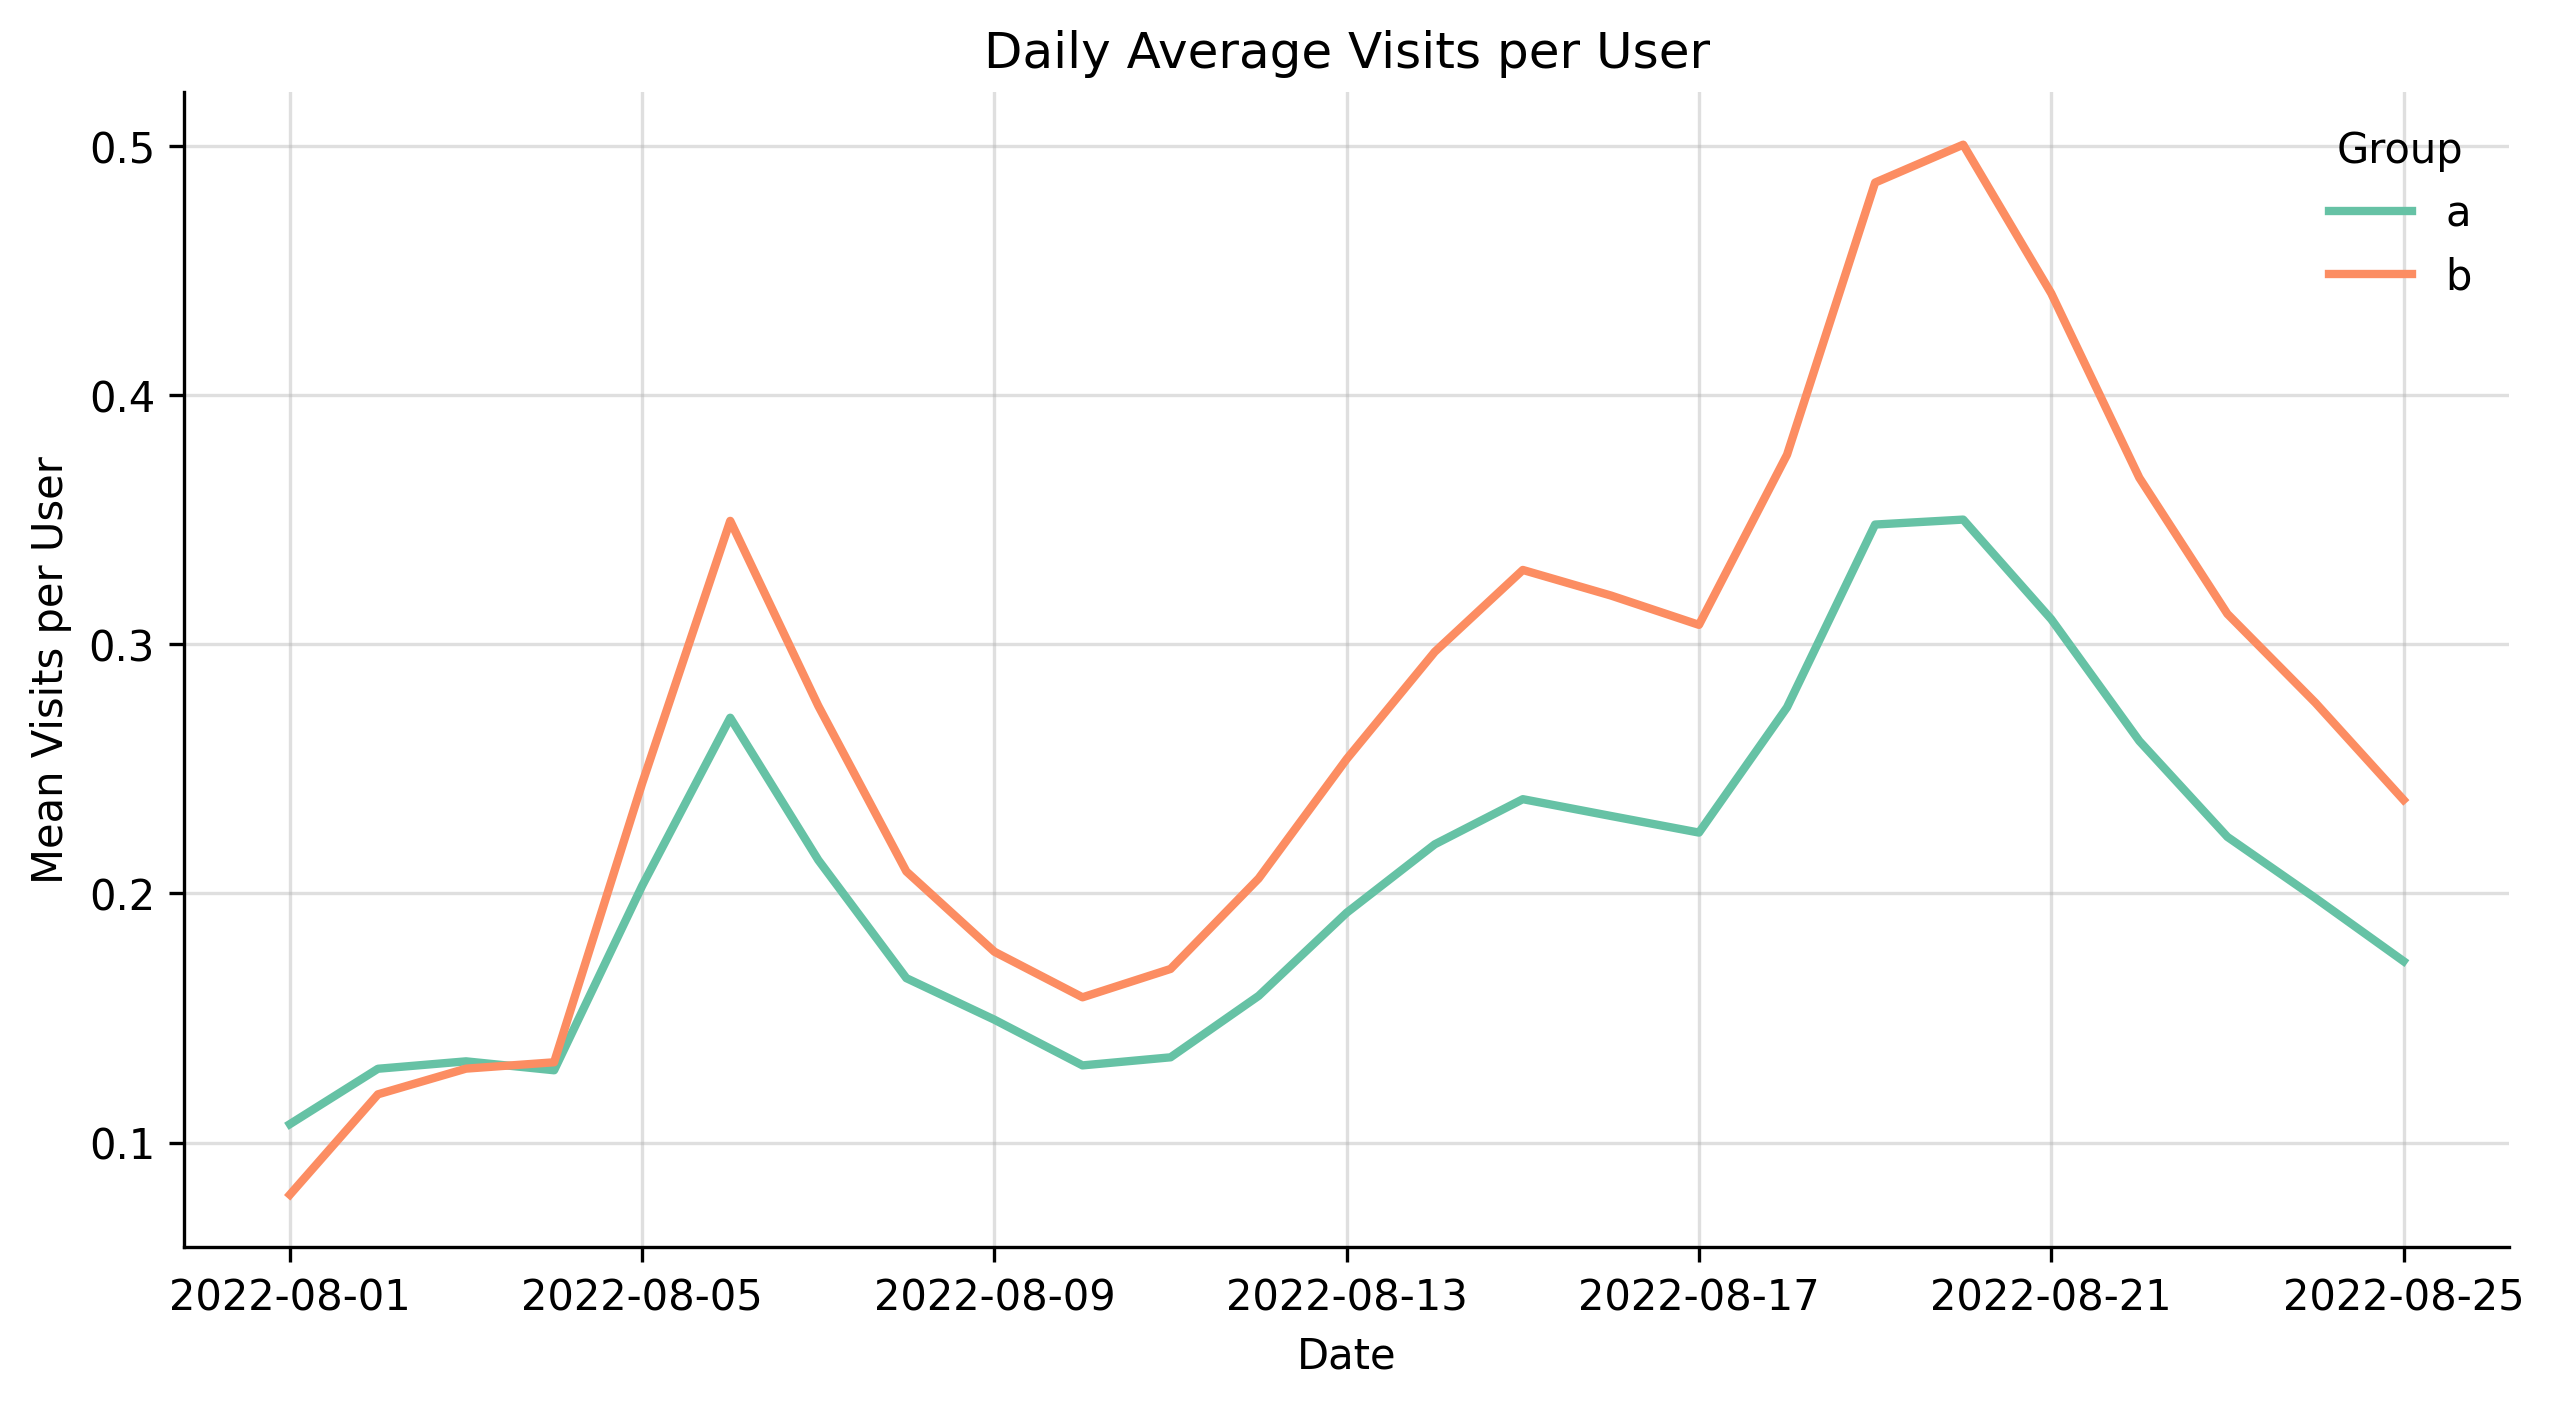

In [ ]:
visits_merged = test_visits.merge(
    users[["id", "split_group"]], left_on="user_id", right_on="id"
)

daily_visits = (
    visits_merged.groupby(["date", "split_group"])["user_id"]
    .count()
    .reset_index()
)
daily_visits["visits_per_user"] = daily_visits.apply(
    lambda row: row["user_id"] / len_group_a
    if row["split_group"] == "a"
    else row["user_id"] / len_group_b,
    axis=1
)


plt.figure(figsize=(10, 5), dpi=300)
sns.lineplot(data=daily_visits, x="date", y="visits_per_user", hue="split_group",
    palette="Set2", linewidth=2)
plt.title("Daily Average Visits per User")
plt.xlabel("Date")
plt.ylabel("Mean Visits per User")
plt.grid(linestyle="-", alpha=0.4)
plt.legend(title="Group", frameon=False)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.show()


The chart above shows consistently better data regarding platform visits. Group B (for which the new functionality is being tested) tends to visit the platform more frequently (with the exception of the first few days of testing).

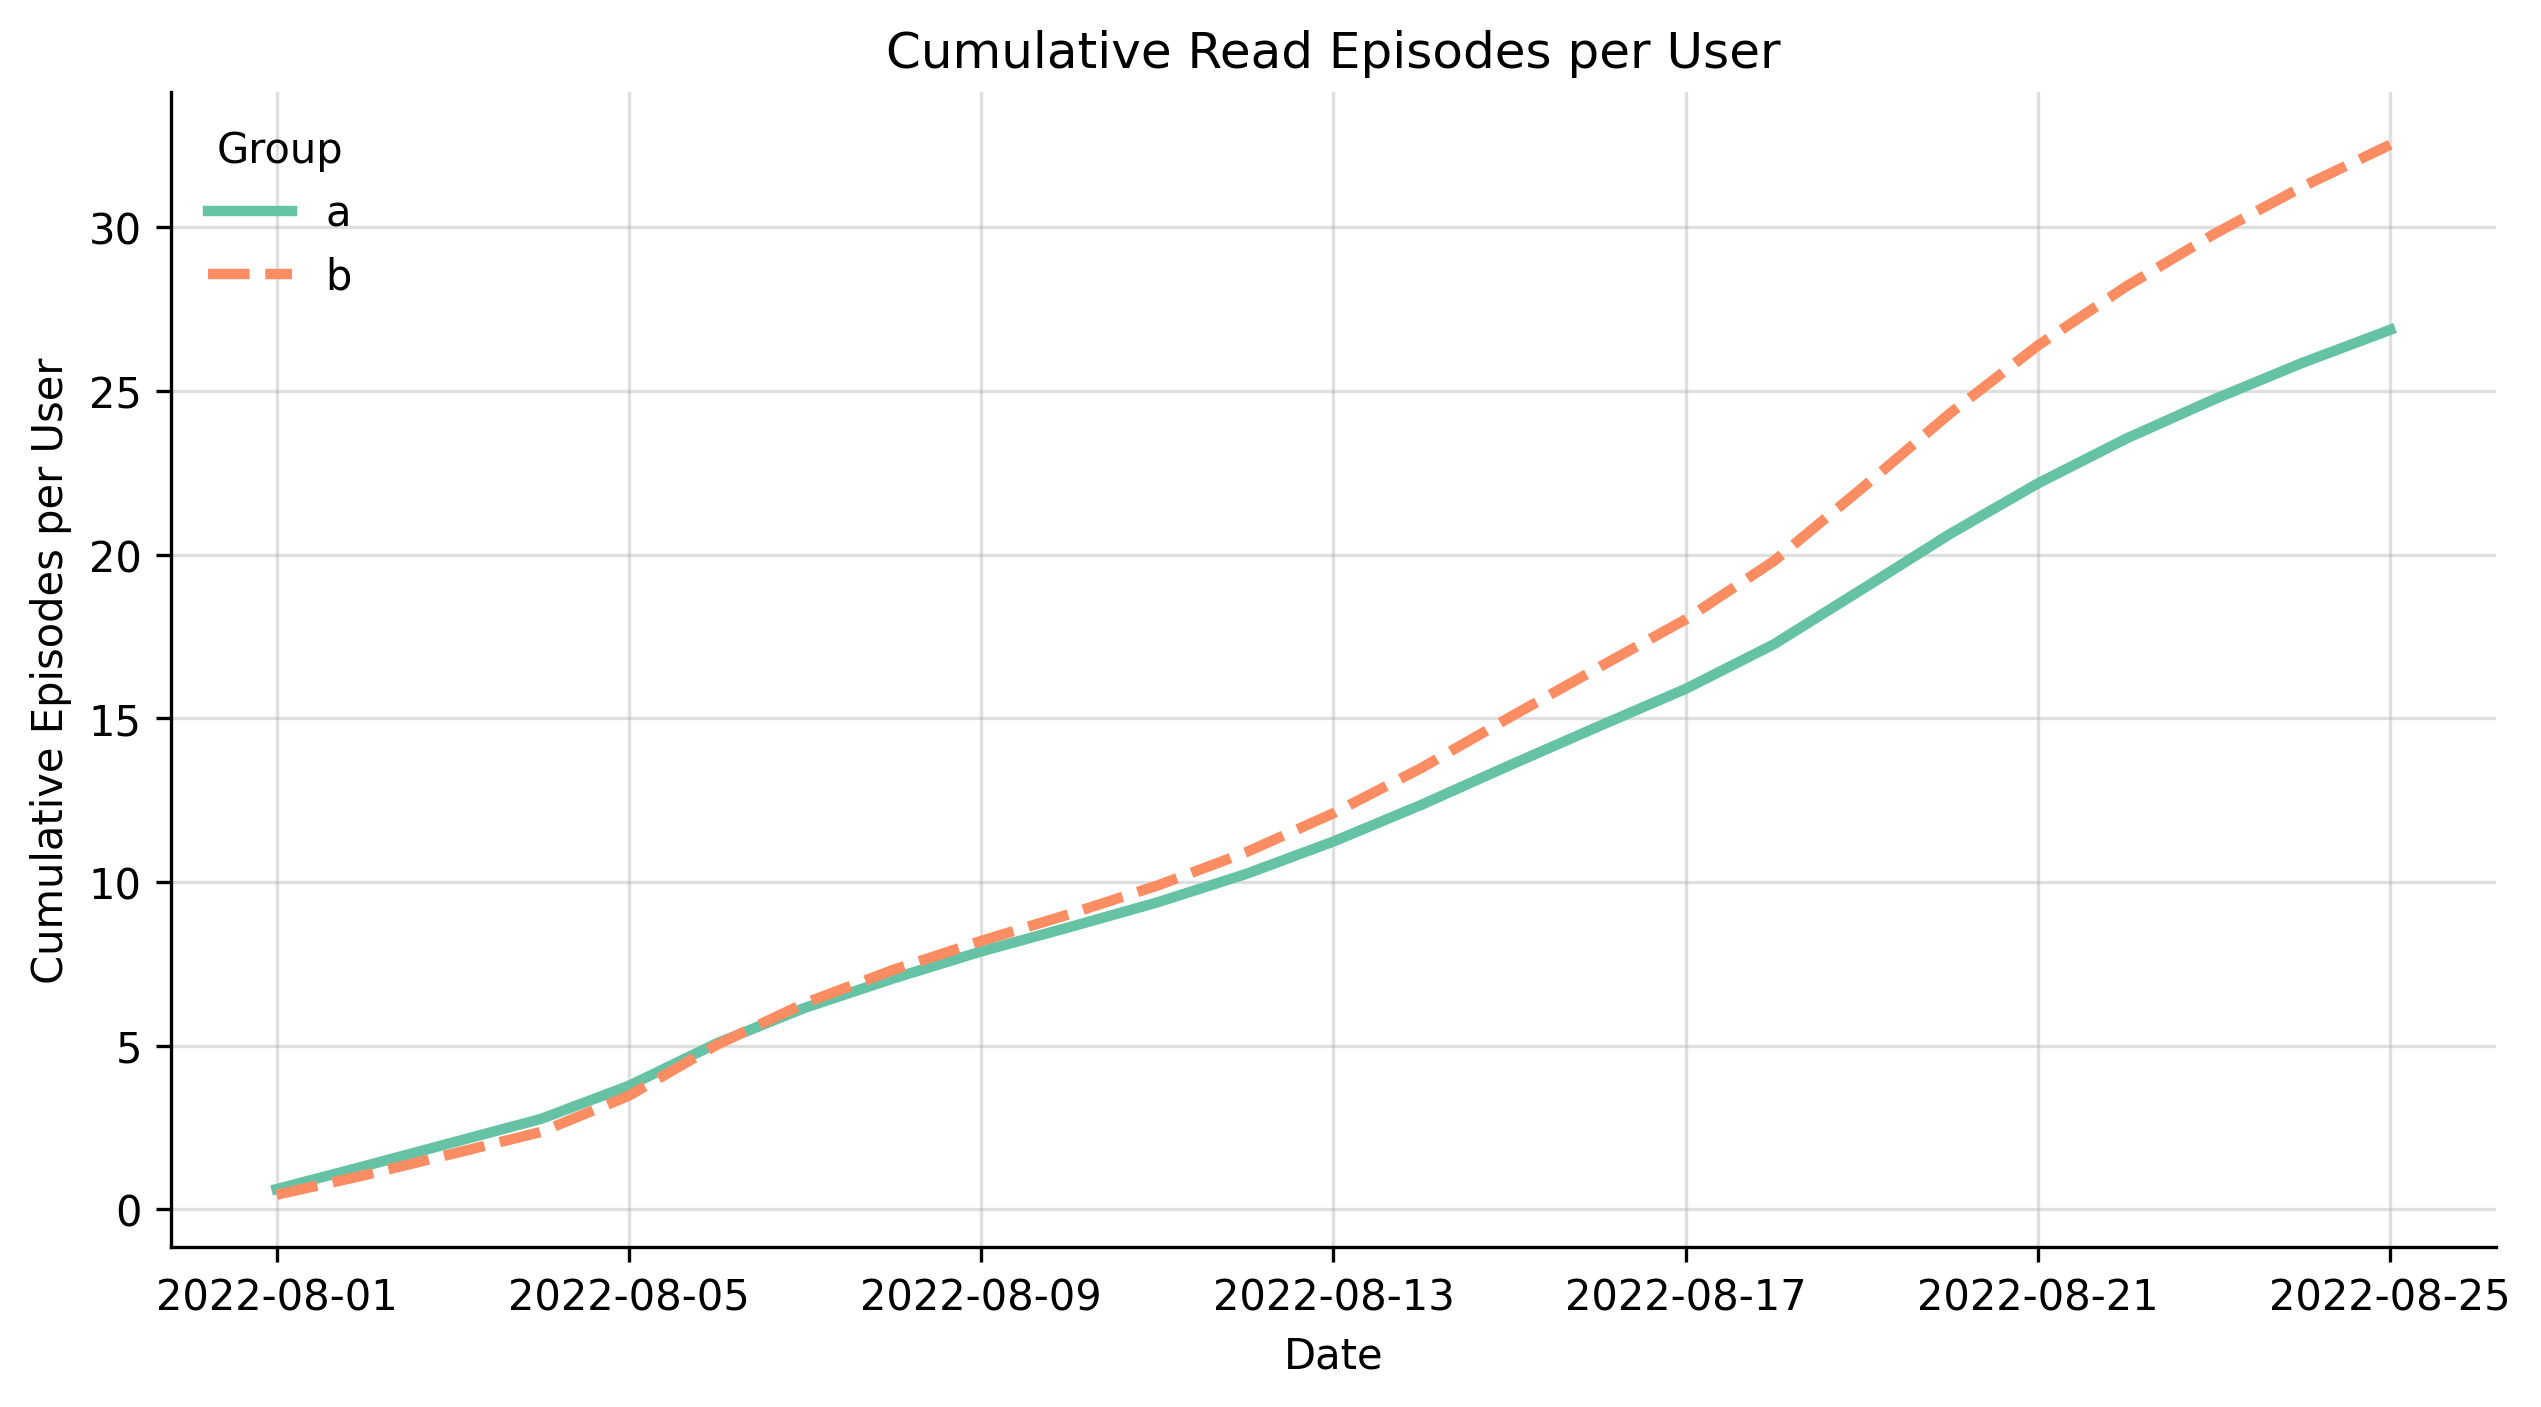

In [ ]:
reading_merged = test_reading_log.merge(
    users[["id", "split_group"]], left_on="user_id", right_on="id"
)

# calculating daily amount of read episodes
daily_episodes = (
    reading_merged.groupby(["date", "split_group"])["count_episodes"]
    .sum()
    .unstack(fill_value=0)
)

# get cumulative sum for each group and then average
cum_episodes = daily_episodes.cumsum()
cum_episodes["a"] = cum_episodes["a"] / len_group_a
cum_episodes["b"] = cum_episodes["b"] / len_group_b

plt.figure(figsize=(10, 5), dpi=300)
sns.lineplot(data=cum_episodes, palette="Set2", linewidth=2.5)
plt.title("Cumulative Read Episodes per User")
plt.xlabel("Date")
plt.ylabel("Cumulative Episodes per User")
plt.grid(linestyle="-", alpha=0.4)
plt.legend(title="Group", frameon=False)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.show()


The provided graph shows more positive activity regarding the reading of episodes in the test group throughout the entire testing period (with the exception of the initial phase, where results were very close to those of the control group).

Based on user visits and comic readership, the following conclusions can be drawn: doubling the frequency of email newsletters significantly increased user engagement (visits rose by ~30%, and episodes read by ~20%).

Furthermore, the p-value (0.0000) indicates that the results are not due to noise, nor are they merely the product of random chance.

# Recommendations / Answers to Questions


It is recommended to continue scaling the email outreach while simultaneously refining the in-app monetization logic; although users are consuming more content, this has not translated into a proportional increase in purchases. It may be worth focusing on optimizing the offers presented within the application itself.

Doubling the frequency of email newsletters did not result in a significant, immediate surge in sales, though it did boost user engagement on the platform. At this stage, while the expanded outreach is highly effective at encouraging users to read comics, the platform is not yet successfully driving sales growth.

Answers to additional questions:
1. Yes, there is sufficient data to make a decision. There are nearly 150,000 users (~89,000 in Group A and ~61,000 in Group B). For a digital platform conducting a test over a period of ~24 days, this constitutes a quite representative sample.

2. Theoretically, given the large sample size (~150,000 users) and the stability of the metrics, it would have been possible to determine the result by day 14–16 of the test, rather than day 25. However, ending the test in less than two full weeks would have been risky, considering the differences in user behavior between weekdays and weekends.

3. A standard t-test shows no immediate, sharp increase in revenue (p = 0.87).
However, after applying the CUPED method to filter out historical user noise, a positive effect was revealed (p = 0.0). This indicates that sending two emails holds potential: it not only boosts user engagement but also has a positive impact on revenue—an effect that was previously obscured.

4. To evaluate a test more quickly and improve its statistical validity, it is advisable to incorporate historical user data from before the experiment began. Applying methods like CUPED allows for the identification of data variance prior to the test. Reducing noise in the data leads to faster, more accurate results, even with a smaller sample size and a shorter timeframe.